# RFM Customer Segmentation using Pandas

## Objective
The objective of this notebook is to perform customer segmentation using the RFM (Recency, Frequency, Monetary) model.

RFM helps businesses identify valuable customers based on:

- **Recency (R):** Number of days since the customer's last purchase.
- **Frequency (F):** Number of unique orders placed by the customer.
- **Monetary (M):** Total amount spent by the customer.

This analysis can help companies identify loyal customers, high-value customers, and customers at risk of leaving.

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

In [6]:
df = pd.read_csv("Sample - Superstore 2019.CSV",encoding="latin1")

In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1.0,CA-2018-152156,08/11/2018,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2.0,CA-2018-152156,08/11/2018,11/11/2018,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3.0,CA-2018-138688,12/06/2018,16/06/2018,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4.0,US-2017-108966,11/10/2017,18/10/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5.0,US-2017-108966,11/10/2017,18/10/2017,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [8]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 9996 entries, 0 to 9995
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          9994 non-null   float64
 1   Order ID        9994 non-null   str    
 2   Order Date      9994 non-null   str    
 3   Ship Date       9994 non-null   str    
 4   Ship Mode       9994 non-null   str    
 5   Customer ID     9994 non-null   str    
 6   Customer Name   9994 non-null   str    
 7   Segment         9994 non-null   str    
 8   Country/Region  9994 non-null   str    
 9   City            9994 non-null   str    
 10  State           9994 non-null   str    
 11  Postal Code     9983 non-null   float64
 12  Region          9994 non-null   str    
 13  Product ID      9994 non-null   str    
 14  Category        9994 non-null   str    
 15  Sub-Category    9994 non-null   str    
 16  Product Name    9994 non-null   str    
 17  Sales           9994 non-null   float64
 18 

In [9]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55245.233297,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:
df.isnull().sum()

Row ID             2
Order ID           2
Order Date         2
Ship Date          2
Ship Mode          2
Customer ID        2
Customer Name      2
Segment            2
Country/Region     2
City               2
State              2
Postal Code       13
Region             2
Product ID         2
Category           2
Sub-Category       2
Product Name       2
Sales              2
Quantity           2
Discount           2
Profit             2
dtype: int64

In [11]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y"
)

In [12]:
analysis_date = df["Order Date"].max() + pd.Timedelta(days=1)

print(analysis_date)

2019-12-31 00:00:00


In [13]:
rfm = df.groupby("Customer ID").agg({

    "Order Date": lambda x: (analysis_date - x.max()).days,

    "Order ID": "nunique",

    "Sales": "sum"

})
rfm

,Order Date,Order ID,Sales
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
...,...,...,...
XP-21865,44,11,2374.658
YC-21895,5,5,5454.350
YS-21880,10,8,6720.444


In [14]:
rfm.columns = [

    "Recency",

    "Frequency",

    "Monetary"

]
rfm

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
...,...,...,...
XP-21865,44,11,2374.658
YC-21895,5,5,5454.350
YS-21880,10,8,6720.444


In [15]:
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156


## Scientific Customer Ranking using the RFM Model

After calculating the Recency, Frequency, and Monetary values, the next step is to rank customers using the RFM Scoring method.

Since the three metrics have different scales, they cannot be compared directly. Therefore, each metric is divided into five equal groups (quintiles) using the `pd.qcut()` function.

- **Recency:** Customers with lower Recency values receive higher scores because they purchased more recently.
- **Frequency:** Customers with higher purchase frequency receive higher scores.
- **Monetary:** Customers with higher total spending receive higher scores.

Each customer receives a score from **1 to 5** for each metric. These three scores are then combined to create the final **RFM Score**, which is used to rank customers and identify valuable customer segments such as Champions, Loyal Customers, and At-Risk Customers.

The `pd.qcut()` function is used because it divides customers into approximately equal-sized groups, making the scoring process fair and suitable for customer segmentation.

In [16]:
#Recency 
rfm["R_Score"] = pd.qcut(

    rfm["Recency"],

    5,

    labels=[5,4,3,2,1]

)

In [17]:
#Frequency 
rfm["F_Score"] = pd.qcut(

    rfm["Frequency"].rank(method="first"),

    5,

    labels=[1,2,3,4,5]

)

In [18]:
#Monetary
rfm["M_Score"] = pd.qcut(

    rfm["Monetary"],

    5,

    labels=[1,2,3,4,5]

)

In [19]:
#final RFM score
rfm["RFM_Score"] = (

    rfm["R_Score"].astype(str)

    + rfm["F_Score"].astype(str)

    + rfm["M_Score"].astype(str)

)

In [20]:
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
AA-10315,185,5,5563.560,2,2,5,225
AA-10375,20,9,1056.390,5,5,2,552
AA-10480,260,4,1790.512,1,1,3,113
AA-10645,56,6,5086.935,3,3,5,335
AB-10015,416,3,886.156,1,1,1,111
AB-10060,55,8,7755.620,3,4,5,345
AB-10105,42,10,14473.571,4,5,5,455
AB-10150,42,5,966.710,4,2,2,422
AB-10165,26,8,1113.838,5,4,2,542


In [21]:
#top 10 customers based on RFM score
rfm.sort_values(

    by="RFM_Score",

    ascending=False

).head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
AH-10210,7,9,4805.3440,5,5,5,555
AI-10855,14,10,4375.7860,5,5,5,555
BF-11170,17,11,5907.9720,5,5,5,555
DK-13225,11,9,4802.3940,5,5,5,555
DR-12880,4,9,6528.0340,5,5,5,555
EP-13915,13,17,5478.0608,5,5,5,555
GZ-14470,8,9,4355.1500,5,5,5,555
HM-14860,3,10,8236.7648,5,5,5,555
JG-15160,2,11,6366.3920,5,5,5,555


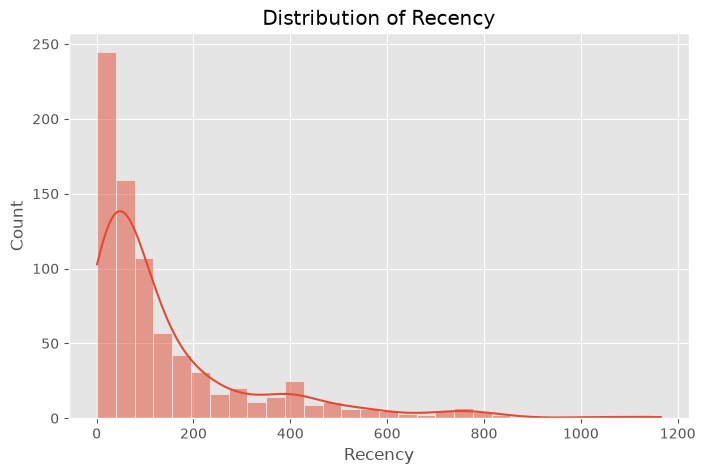

In [22]:
#vesual 1 (Distribution of Recency)
plt.figure(figsize=(8,5))

sns.histplot(

    rfm["Recency"],

    bins=30,

    kde=True

)

plt.title("Distribution of Recency")

plt.show()

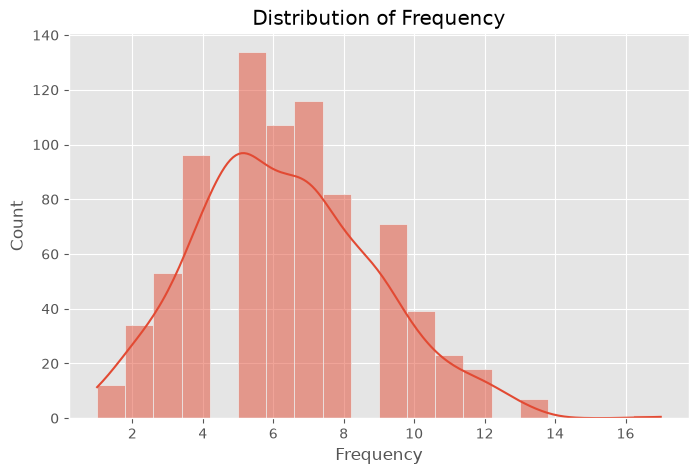

In [23]:
#vesual 2 (Distribution of Frequency)
plt.figure(figsize=(8,5))

sns.histplot(

    rfm["Frequency"],

    bins=20,

    kde=True

)

plt.title("Distribution of Frequency")

plt.show()

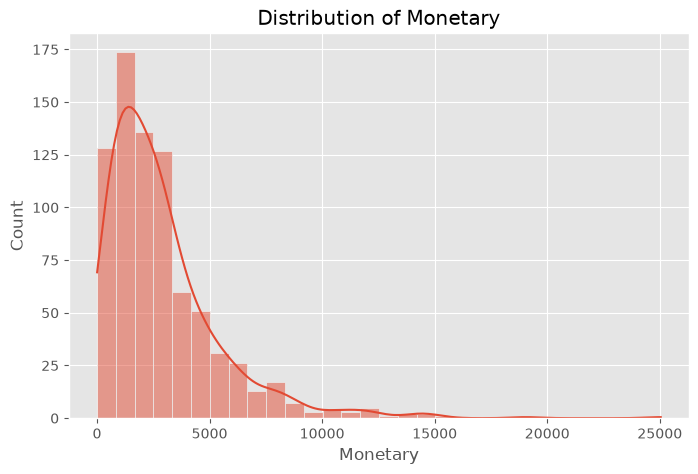

In [24]:
#vesual 3 (Distribution of Monetary)
plt.figure(figsize=(8,5))

sns.histplot(

    rfm["Monetary"],

    bins=30,

    kde=True

)

plt.title("Distribution of Monetary")

plt.show()

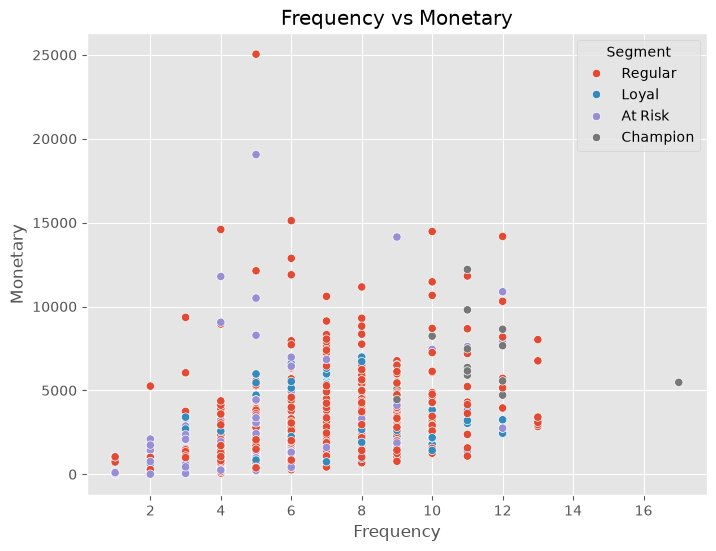

In [33]:
#visual 4 (Frequency vs Monetary)
plt.figure(figsize=(8,6))

sns.scatterplot(

    data=rfm,

    x="Frequency",

    y="Monetary",
    hue="Segment"
    
)

plt.title("Frequency vs Monetary")

plt.show()

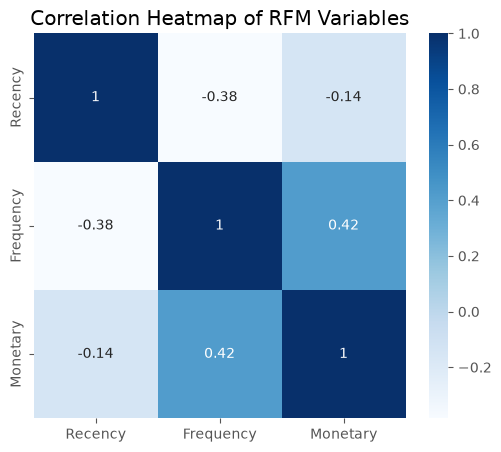

In [32]:
#visual 5(Correlation Heatmap)
plt.figure(figsize=(6,5))

sns.heatmap(

    rfm[["Recency","Frequency","Monetary"]].corr(),

    annot=True,

    cmap="Blues"

)
plt.title("Correlation Heatmap of RFM Variables")


plt.show()

In [ ]:
def segment_customer(score):

    if score == "555":
        return "Champion"

    elif score.startswith("5"):
        return "Loyal"

    elif score.startswith("1"):
        return "At Risk"

    else:
        return "Regular"
rfm["Segment"] = rfm["RFM_Score"].apply(segment_customer)

rfm["Segment"] 

Customer ID
AA-10315    Regular
AA-10375      Loyal
AA-10480    At Risk
AA-10645    Regular
AB-10015    At Risk
             ...   
XP-21865    Regular
YC-21895      Loyal
YS-21880      Loyal
ZC-21910    Regular
ZD-21925    Regular
Name: Segment, Length: 793, dtype: str

In [29]:
rfm["Segment"].value_counts()

Segment
Regular     472
At Risk     159
Loyal       140
Champion     22
Name: count, dtype: int64

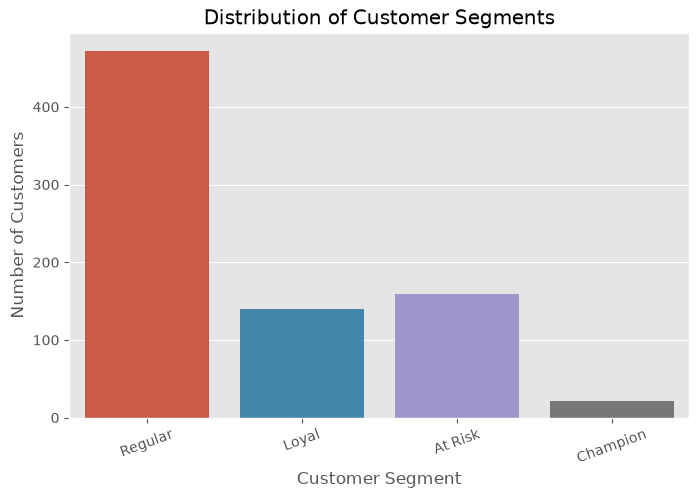

In [31]:
plt.figure(figsize=(8,5))

sns.countplot(data=rfm, x="Segment", hue="Segment", legend=False)

plt.title("Distribution of Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.show()

# Conclusion

- Customers with lower Recency values are more active.
- Higher Frequency indicates loyal customers.
- Higher Monetary values indicate customers with greater business value.
- RFM scoring helps businesses prioritize customers for marketing campaigns and retention strategies.